<a href="https://colab.research.google.com/github/bagas-rafa-hafiz/praktikum-5-6/blob/main/Praktikum_5_6_Pengolahan_Citra_Digital_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Import library
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

print("Library siap digunakan.")

Library siap digunakan.


## 2. Unggah gambar

Saving WhatsApp Image 2025-06-01 at 14.12.35_64994ca3.jpg to WhatsApp Image 2025-06-01 at 14.12.35_64994ca3.jpg
Nama file: WhatsApp Image 2025-06-01 at 14.12.35_64994ca3.jpg
Ukuran gambar: 2316 x 3088 piksel


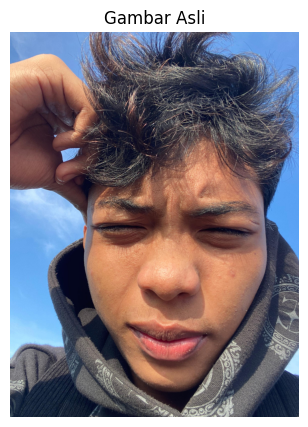

In [2]:
# Pilih gambar dari komputer/laptop
uploaded = files.upload()

if not uploaded:
    raise ValueError("Belum ada gambar yang diunggah.")

filename = next(iter(uploaded))
image_bytes = np.frombuffer(uploaded[filename], np.uint8)
img = cv2.imdecode(image_bytes, cv2.IMREAD_COLOR)

if img is None:
    raise ValueError("File tidak dapat dibaca sebagai gambar. Coba gunakan JPG atau PNG.")

# OpenCV membaca gambar dalam format BGR; ubah ke RGB untuk ditampilkan dengan Matplotlib
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print(f"Nama file: {filename}")
print(f"Ukuran gambar: {img.shape[1]} x {img.shape[0]} piksel")

plt.figure(figsize=(7, 5))
plt.imshow(img)
plt.title("Gambar Asli")
plt.axis("off")
plt.show()

## Fungsi bantu untuk menampilkan hasil

In [3]:
def tampilkan(judul, gambar, figsize=(7, 5)):
    """Menampilkan gambar dengan Matplotlib."""
    plt.figure(figsize=figsize)
    plt.imshow(gambar)
    plt.title(judul)
    plt.axis("off")
    plt.show()


def simpan_gambar(nama_file, gambar):
    """Menyimpan gambar RGB sebagai file PNG."""
    gambar_bgr = cv2.cvtColor(gambar, cv2.COLOR_RGB2BGR)
    cv2.imwrite(nama_file, gambar_bgr)
    print(f"Gambar tersimpan: {nama_file}")

## 3. Translasi Citra (soal 1.a)
Translasi menggeser posisi gambar pada sumbu X dan Y. Nilai positif X menggeser ke kanan, sedangkan nilai positif Y menggeser ke bawah.

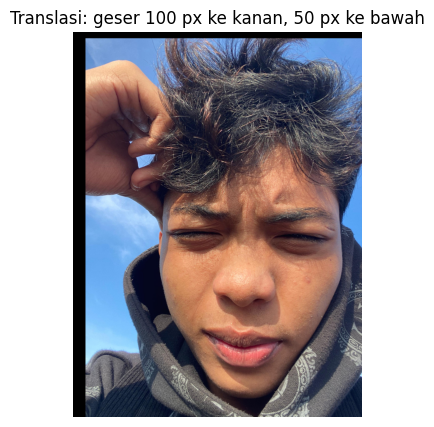

Gambar tersimpan: hasil_translasi.png


In [4]:
def translasi(gambar, tx=100, ty=50):
    tinggi, lebar = gambar.shape[:2]
    matriks = np.float32([[1, 0, tx],
                          [0, 1, ty]])
    hasil = cv2.warpAffine(
        gambar, matriks, (lebar, tinggi),
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0)
    )
    return hasil

hasil_translasi = translasi(img, tx=100, ty=50)
tampilkan("Translasi: geser 100 px ke kanan, 50 px ke bawah", hasil_translasi)
simpan_gambar("hasil_translasi.png", hasil_translasi)

## 4. Mirroring (soal 1.b)
- Horizontal: membalik kiri ke kanan.
- Vertical: membalik atas ke bawah.

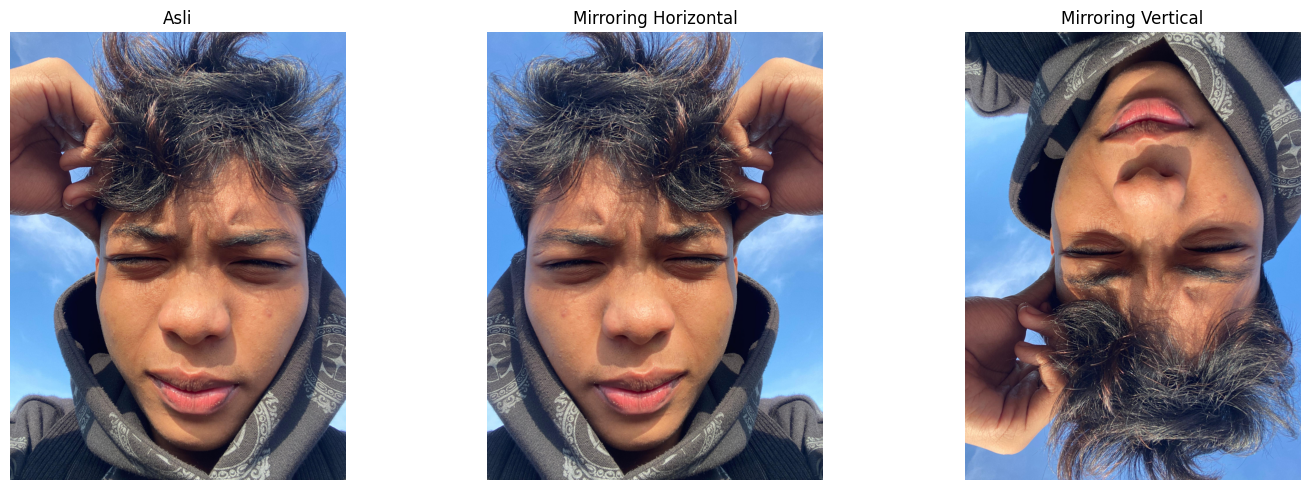

Gambar tersimpan: hasil_mirroring_horizontal.png
Gambar tersimpan: hasil_mirroring_vertical.png


In [5]:
def mirroring_horizontal(gambar):
    return cv2.flip(gambar, 1)

def mirroring_vertical(gambar):
    return cv2.flip(gambar, 0)

hasil_mirror_h = mirroring_horizontal(img)
hasil_mirror_v = mirroring_vertical(img)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img); axes[0].set_title("Asli")
axes[1].imshow(hasil_mirror_h); axes[1].set_title("Mirroring Horizontal")
axes[2].imshow(hasil_mirror_v); axes[2].set_title("Mirroring Vertical")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

simpan_gambar("hasil_mirroring_horizontal.png", hasil_mirror_h)
simpan_gambar("hasil_mirroring_vertical.png", hasil_mirror_v)

## 5. Rotasi Citra (soal 1.c)
Rotasi standar menggunakan titik tengah gambar sebagai pivot. Sudut positif pada OpenCV memutar berlawanan arah jarum jam pada koordinat tampilan.

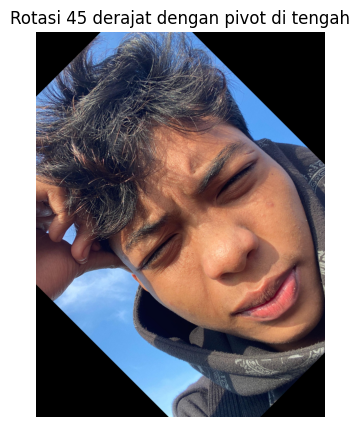

Gambar tersimpan: hasil_rotasi.png


In [6]:
def rotasi_tengah(gambar, sudut=45):
    tinggi, lebar = gambar.shape[:2]
    pusat = (lebar / 2, tinggi / 2)
    matriks = cv2.getRotationMatrix2D(pusat, sudut, 1.0)
    hasil = cv2.warpAffine(
        gambar, matriks, (lebar, tinggi),
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0)
    )
    return hasil

hasil_rotasi = rotasi_tengah(img, sudut=45)
tampilkan("Rotasi 45 derajat dengan pivot di tengah", hasil_rotasi)
simpan_gambar("hasil_rotasi.png", hasil_rotasi)

## 6. Zooming (soal 1.d)
Zoom plus memperbesar gambar. Agar ukuran keluaran tetap sama dengan gambar asli, bagian tengah hasil pembesaran dipotong.

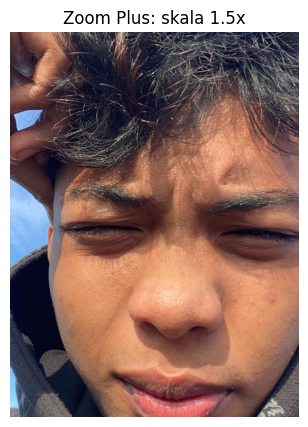

Gambar tersimpan: hasil_zoom_plus.png


In [7]:
def zoom_plus(gambar, skala=1.5):
    if skala <= 1:
        raise ValueError("Untuk zoom plus, skala harus lebih besar dari 1.")
    tinggi, lebar = gambar.shape[:2]
    baru = cv2.resize(gambar, None, fx=skala, fy=skala, interpolation=cv2.INTER_CUBIC)
    h_baru, w_baru = baru.shape[:2]

    y_awal = max((h_baru - tinggi) // 2, 0)
    x_awal = max((w_baru - lebar) // 2, 0)
    hasil = baru[y_awal:y_awal + tinggi, x_awal:x_awal + lebar]

    # Pengaman agar ukuran keluaran selalu sama dengan ukuran awal
    if hasil.shape[:2] != (tinggi, lebar):
        hasil = cv2.resize(hasil, (lebar, tinggi), interpolation=cv2.INTER_CUBIC)
    return hasil

hasil_zoom_plus = zoom_plus(img, skala=1.5)
tampilkan("Zoom Plus: skala 1.5x", hasil_zoom_plus)
simpan_gambar("hasil_zoom_plus.png", hasil_zoom_plus)

## 7. Mirroring horizontal dan vertical bersamaan (soal 2.a)
Mirroring dua arah dilakukan dalam satu operasi. `cv2.flip(gambar, -1)` membalik citra secara horizontal dan vertical sekaligus.

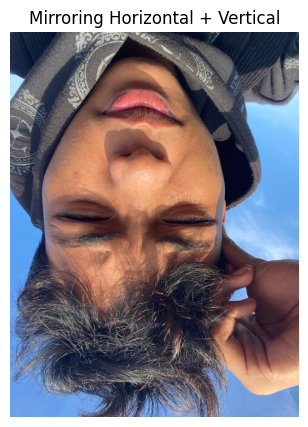

Gambar tersimpan: hasil_mirroring_horizontal_vertical.png


In [8]:
def mirroring_horizontal_vertical(gambar):
    return cv2.flip(gambar, -1)

hasil_mirror_bersamaan = mirroring_horizontal_vertical(img)
tampilkan("Mirroring Horizontal + Vertical", hasil_mirror_bersamaan)
simpan_gambar("hasil_mirroring_horizontal_vertical.png", hasil_mirror_bersamaan)

## 8. Rotasi dengan pivot (0, 0) di pojok kiri atas (soal 2.b)
Berbeda dari rotasi standar, titik pusat rotasi ditetapkan pada koordinat `(0, 0)`, yaitu pojok kiri atas. Karena kanvas tetap sebesar gambar asli, sebagian hasil rotasi mungkin terpotong.

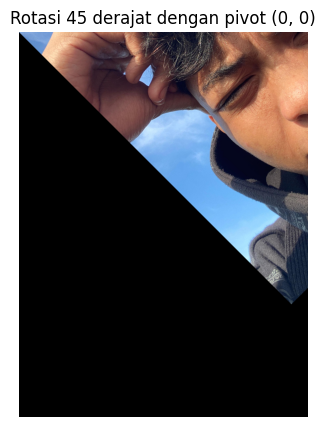

Gambar tersimpan: hasil_rotasi_pivot_0_0.png


In [9]:
def rotasi_pivot_kiri_atas(gambar, sudut=45):
    tinggi, lebar = gambar.shape[:2]
    pivot = (0, 0)
    matriks = cv2.getRotationMatrix2D(pivot, sudut, 1.0)
    hasil = cv2.warpAffine(
        gambar, matriks, (lebar, tinggi),
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0)
    )
    return hasil

hasil_rotasi_pivot = rotasi_pivot_kiri_atas(img, sudut=45)
tampilkan("Rotasi 45 derajat dengan pivot (0, 0)", hasil_rotasi_pivot)
simpan_gambar("hasil_rotasi_pivot_0_0.png", hasil_rotasi_pivot)

## 9. Zoom Minus untuk memperkecil gambar (soal 2.c)
Zoom minus mengecilkan objek di dalam kanvas dengan ukuran tetap. Area kosong di sekeliling objek diisi warna hitam.

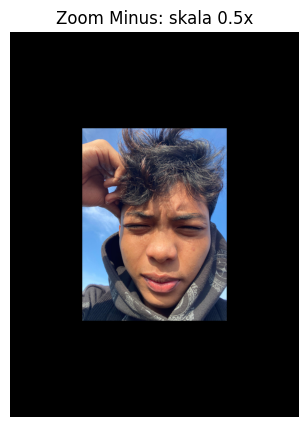

Gambar tersimpan: hasil_zoom_minus.png


In [10]:
def zoom_minus(gambar, skala=0.5):
    if not 0 < skala < 1:
        raise ValueError("Untuk zoom minus, skala harus di antara 0 dan 1.")
    tinggi, lebar = gambar.shape[:2]
    kecil = cv2.resize(gambar, None, fx=skala, fy=skala, interpolation=cv2.INTER_AREA)

    hasil = np.zeros_like(gambar)
    h_kecil, w_kecil = kecil.shape[:2]
    y_awal = (tinggi - h_kecil) // 2
    x_awal = (lebar - w_kecil) // 2
    hasil[y_awal:y_awal + h_kecil, x_awal:x_awal + w_kecil] = kecil
    return hasil

hasil_zoom_minus = zoom_minus(img, skala=0.5)
tampilkan("Zoom Minus: skala 0.5x", hasil_zoom_minus)
simpan_gambar("hasil_zoom_minus.png", hasil_zoom_minus)

## 10. Ringkasan hasil
Jalankan sel berikut untuk melihat ringkasan semua hasil transformasi.

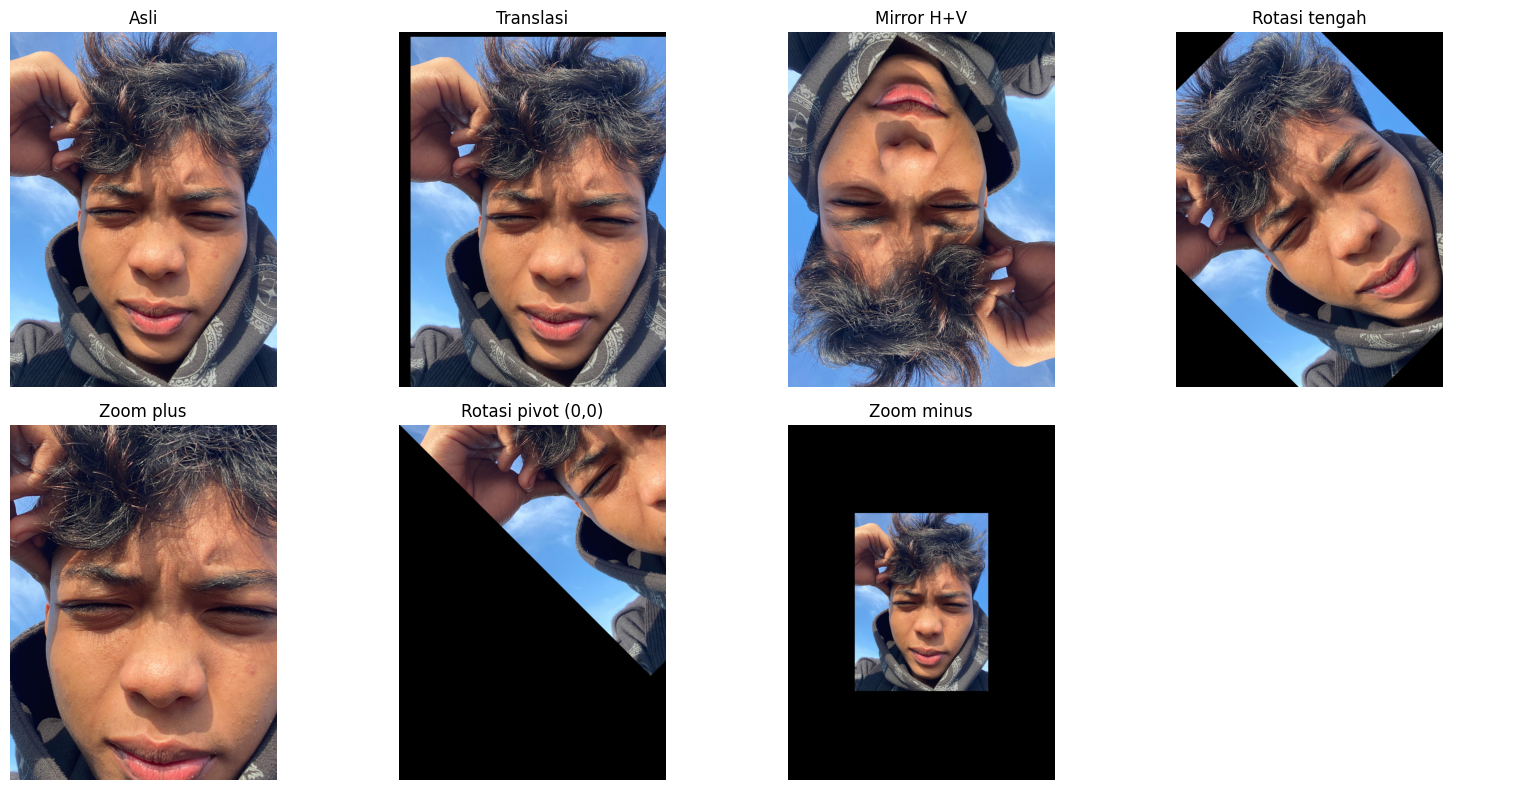

In [11]:
hasil_semua = [
    ("Asli", img),
    ("Translasi", hasil_translasi),
    ("Mirror H+V", hasil_mirror_bersamaan),
    ("Rotasi tengah", hasil_rotasi),
    ("Zoom plus", hasil_zoom_plus),
    ("Rotasi pivot (0,0)", hasil_rotasi_pivot),
    ("Zoom minus", hasil_zoom_minus),
]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (judul, gambar) in zip(axes.ravel(), hasil_semua):
    ax.imshow(gambar)
    ax.set_title(judul)
    ax.axis("off")

# Matikan panel terakhir yang tidak terpakai
for ax in axes.ravel()[len(hasil_semua):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 11. Unduh hasil gambar (opsional)
Jalankan sel ini untuk mengunduh satu hasil tertentu. Ganti nama file sesuai hasil yang ingin diunduh.

In [12]:
# Contoh: unduh hasil zoom minus
files.download("hasil_zoom_minus.png")

# Untuk hasil lain, gunakan salah satu nama file:
# hasil_translasi.png
# hasil_mirroring_horizontal.png
# hasil_mirroring_vertical.png
# hasil_rotasi.png
# hasil_zoom_plus.png
# hasil_mirroring_horizontal_vertical.png
# hasil_rotasi_pivot_0_0.png

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>